# Exploratory analysis

**Synthetic data, fictional company.** "Lumen Labs" and its product "Relay" do not exist. Every account in this notebook is generated.

Before any play is designed, look at the data. This notebook asks six questions of the gold tables:

1. Who are the customers, and where is the coverage gap?
2. What does usage look like, and how do accounts group by behaviour?
3. Where are accounts in their lifecycle?
4. Do the signals predict churn and expansion? (If they do not, no play should be built on them.)
5. Do the health score and the churn model separate accounts that leave from accounts that stay?
6. What did data quality catch on the way in?

A last section compares the scores with the simulator's hidden state. That is a check that only exists because this is a simulation. It is the only part of the project, with `analytics/eda.py`, that reads `data/ground_truth/`, and nothing it reads goes back into the pipeline, the models or the agents.

To run it again: `uv run --group notebook jupyter nbconvert --to notebook --execute --inplace analytics/01_eda.ipynb`. The same tables, as plain text, are in `docs/eda-report.md` (written by `analytics/eda.py`).

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# The notebook may be started from the project folder or from analytics/.
ROOT = Path.cwd() if (Path.cwd() / "run.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from common.paths import DATA_DIR  # noqa: E402
from ingest.load import warehouse_path  # noqa: E402

con = duckdb.connect(str(warehouse_path(DATA_DIR)), read_only=True)  # we only read


def query(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
today = query("SELECT max(snapshot_date) AS day FROM gold.account_current")["day"][0].date()
print(f"Today in the warehouse (the simulated calendar): {today}")

Today in the warehouse (the simulated calendar): 2026-10-27


## 1. Who are the customers, and where is the coverage gap?

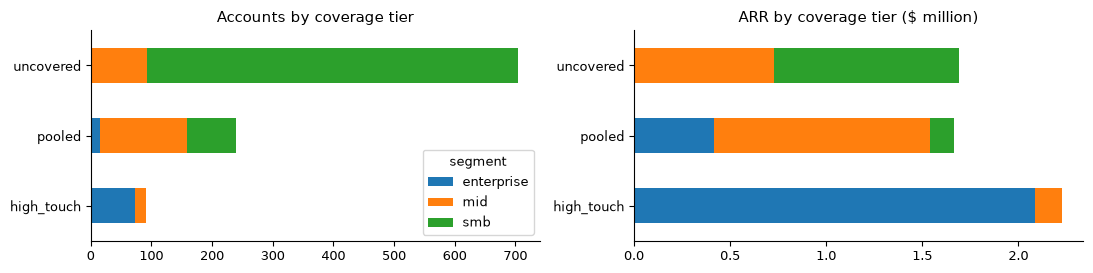

Uncovered accounts: 68% of accounts, 30% of ARR. Nobody is assigned to them.


In [2]:
base = query(
    """
    SELECT coverage_tier, segment, count(*) AS accounts, sum(arr) AS arr
    FROM gold.account_current GROUP BY ALL ORDER BY coverage_tier, segment
    """
)
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 2.8))
base.pivot(index="coverage_tier", columns="segment", values="accounts").plot.barh(
    stacked=True, ax=left, title="Accounts by coverage tier"
)
base.pivot(index="coverage_tier", columns="segment", values="arr").div(1e6).plot.barh(
    stacked=True, ax=right, title="ARR by coverage tier ($ million)", legend=False
)
left.set_ylabel("")
right.set_ylabel("")
plt.tight_layout()
plt.show()

by_tier = base.groupby("coverage_tier")[["accounts", "arr"]].sum()
share = by_tier / by_tier.sum()
print(
    f"Uncovered accounts: {share.loc['uncovered', 'accounts']:.0%} of accounts, "
    f"{share.loc['uncovered', 'arr']:.0%} of ARR. Nobody is assigned to them."
)

**Reading.** Most accounts have no named success manager, and together they hold a real share of the revenue. People cannot cover them one by one, so this is where a digital and agent-led programme has to work. The pilot runs on this tier.

## 2. What does usage look like?

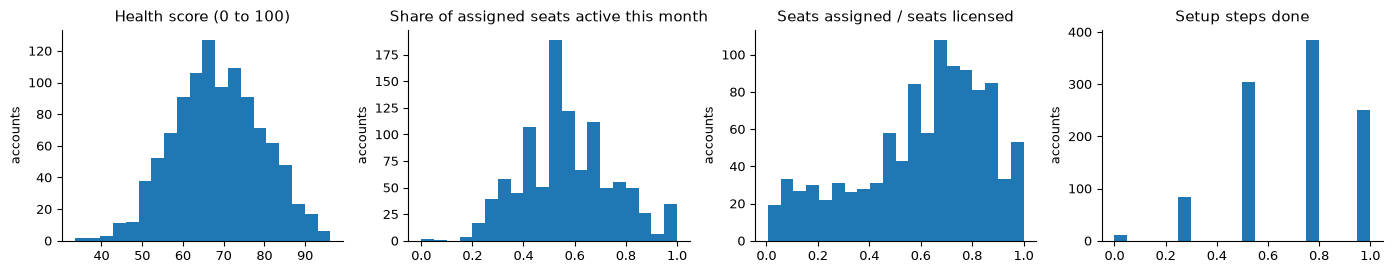

,health_score,active_seat_share,seat_utilisation,prerequisite_closure_pct
segment,,,,
enterprise,66.98,0.47,0.52,0.67
mid,68.16,0.54,0.55,0.69
smb,68.90,0.59,0.65,0.69


In [3]:
accounts = query("SELECT * FROM gold.account_current")
accounts["active_seat_share"] = accounts["mau_30d"] / accounts["seats_assigned"]

figure, axes = plt.subplots(1, 4, figsize=(14, 2.8))
charts = {
    "health_score": "Health score (0 to 100)",
    "active_seat_share": "Share of assigned seats active this month",
    "seat_utilisation": "Seats assigned / seats licensed",
    "prerequisite_closure_pct": "Setup steps done",
}
for axis, (column, title) in zip(axes, charts.items(), strict=True):
    accounts[column].plot.hist(bins=20, ax=axis, title=title)
    axis.set_ylabel("accounts")
plt.tight_layout()
plt.show()

by_segment = accounts.groupby("segment")[list(charts)].mean().round(2)
by_segment

**Reading.** Setup is lumpy: an account has done 0, 1, 2, 3 or 4 of the four setup steps, and a large group is stuck part of the way. That is the audience of the onboarding play. Segments differ little on average, so the plays are targeted on behaviour, not on size.

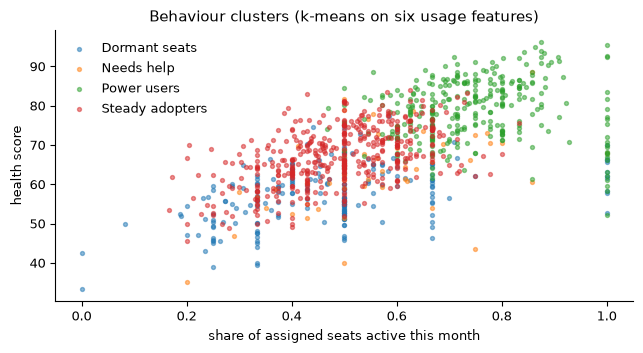

,accounts,active_seat_share,tickets_30d,health_score
behaviour_cluster,,,,
Steady adopters,446,0.49,0.51,67.07
Power users,317,0.74,0.44,78.98
Dormant seats,221,0.47,0.50,57.82
Needs help,52,0.56,4.56,63.26


In [4]:
clusters = (
    accounts.groupby("behaviour_cluster")
    .agg(
        accounts=("account_id", "count"),
        active_seat_share=("active_seat_share", "mean"),
        tickets_30d=("tickets_30d", "mean"),
        health_score=("health_score", "mean"),
    )
    .round(2)
    .sort_values("accounts", ascending=False)
)

figure, axis = plt.subplots(figsize=(6.5, 3.6))
for name, group in accounts.groupby("behaviour_cluster"):
    axis.scatter(group["active_seat_share"], group["health_score"], s=8, alpha=0.5, label=name)
axis.set_xlabel("share of assigned seats active this month")
axis.set_ylabel("health score")
axis.set_title("Behaviour clusters (k-means on six usage features)")
axis.legend(frameon=False)
plt.tight_layout()
plt.show()
clusters

**Reading.** The clusters have plain names because a play owner has to act on them. "Dormant seats" pay for seats nobody uses: a churn risk at renewal. "Needs help" raise many tickets. The clusters describe; they do not trigger plays. Signals do that, and section 4 checks the signals.

## 3. Where are accounts in their lifecycle?

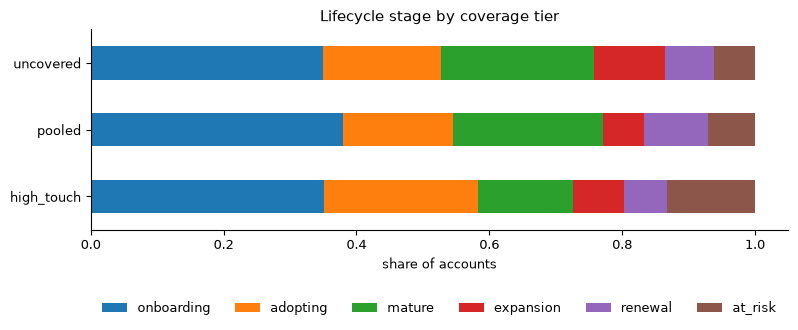

lifecycle_stage,onboarding,adopting,mature,expansion,renewal,at_risk
coverage_tier,,,,,,
high_touch,32,21,13,7,6,12
pooled,91,40,54,15,23,17
uncovered,247,125,162,76,52,43


In [5]:
stages = query(
    """
    SELECT coverage_tier, lifecycle_stage, count(*) AS accounts
    FROM gold.account_current GROUP BY ALL
    """
).pivot(index="coverage_tier", columns="lifecycle_stage", values="accounts").fillna(0)

order = ["onboarding", "adopting", "mature", "expansion", "renewal", "at_risk"]
share = stages[order].div(stages[order].sum(axis=1), axis=0)
axis = share.plot.barh(stacked=True, figsize=(9, 2.6), title="Lifecycle stage by coverage tier")
axis.set_xlabel("share of accounts")
axis.set_ylabel("")
axis.legend(ncols=6, loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
plt.show()
stages[order].astype(int)

**Reading.** One stage per account, decided by rules with a fixed order (`docs/metrics.md`). The uncovered tier has the largest share still onboarding: accounts that never finished setup stay in onboarding however old they are.

## 4. Do the signals predict outcomes?

Take the latest day whose following 90 days are fully known. Split accounts by whether each signal was firing that day, and compare what happened next with the average account. A lift of 1 means the signal tells us nothing.

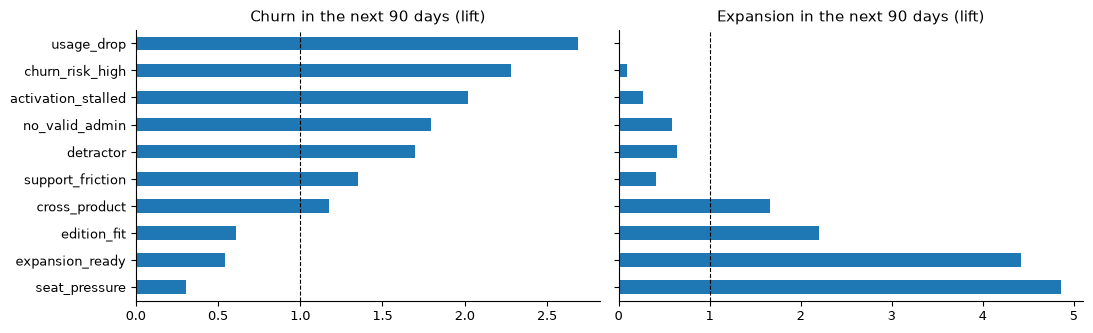

Accounts on 2026-07-29, by signal firing that day:


,accounts,churn_lift,expansion_lift
signal,,,
seat_pressure,64,0.3,4.9
expansion_ready,72,0.5,4.4
edition_fit,64,0.6,2.2
cross_product,58,1.2,1.7
support_friction,36,1.4,0.4
detractor,23,1.7,0.6
no_valid_admin,38,1.8,0.6
activation_stalled,82,2.0,0.3
churn_risk_high,77,2.3,0.1


In [6]:
test_day = query(
    "SELECT max(snapshot_date) AS day FROM gold.fct_outcome_labels WHERE outcome_observed"
)["day"][0].date()

signals = query(
    f"""
    WITH day AS (
        SELECT account_id, churned_within_90d, expanded_within_90d
        FROM gold.fct_outcome_labels WHERE snapshot_date = DATE '{test_day}'
    ),
    base AS (
        SELECT avg(churned_within_90d::INT) AS churn, avg(expanded_within_90d::INT) AS expand
        FROM day
    )
    SELECT signals.signal_id AS signal,
           count(*) AS accounts,
           avg(day.churned_within_90d::INT) / any_value(base.churn) AS churn_lift,
           avg(day.expanded_within_90d::INT) / any_value(base.expand) AS expansion_lift
    FROM gold.signals AS signals
    INNER JOIN day ON signals.account_id = day.account_id
    CROSS JOIN base
    WHERE signals.snapshot_date = DATE '{test_day}'
    GROUP BY signals.signal_id
    ORDER BY churn_lift
    """
).set_index("signal")

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
signals["churn_lift"].plot.barh(ax=left, title="Churn in the next 90 days (lift)")
signals["expansion_lift"].plot.barh(ax=right, title="Expansion in the next 90 days (lift)")
for axis in (left, right):
    axis.axvline(1, color="black", linewidth=0.8, linestyle="--")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()
print(f"Accounts on {test_day}, by signal firing that day:")
signals.round(1)

**Reading.** The signals built for risk (stalled activation, usage drop, a detractor score) lift churn and do not lift expansion. The signals built for growth (seat pressure, edition fit) do the opposite. Each play is triggered by a signal that points the right way. The two model signals are partly in-sample here; the clean test is in the model cards (`docs/model-cards/`).

## 5. Do the health score and the churn model separate leavers from stayers?

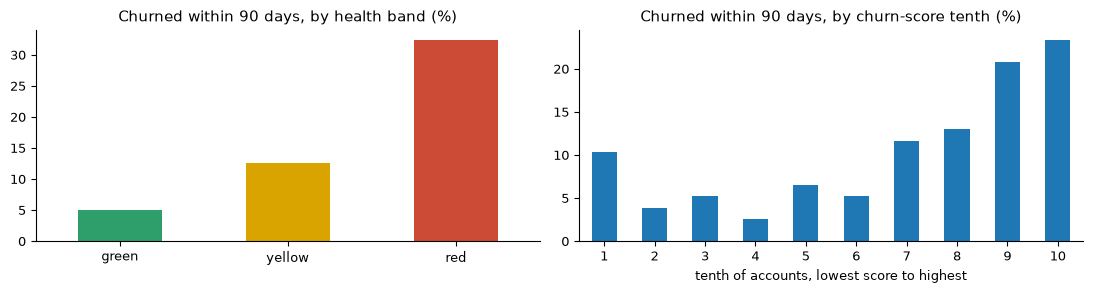

The top tenth by churn score churns 2.3 times as often as the average account.


In [7]:
scored = query(
    f"""
    SELECT facts.health_band, facts.churn_risk_score, labels.churned_within_90d
    FROM gold.account_daily AS facts
    INNER JOIN gold.fct_outcome_labels AS labels
        ON facts.account_id = labels.account_id AND facts.snapshot_date = labels.snapshot_date
    WHERE facts.snapshot_date = DATE '{test_day}'
    """
)
bands = ["green", "yellow", "red"]
by_band = scored.groupby("health_band")["churned_within_90d"].mean().reindex(bands)
ranked = scored["churn_risk_score"].rank(method="first")
scored["score_group"] = pd.qcut(ranked, 10, labels=False) + 1
by_group = scored.groupby("score_group")["churned_within_90d"].mean()

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3))
by_band.mul(100).plot.bar(ax=left, color=["#2e9e6b", "#d9a400", "#cc4b37"], rot=0)
left.set_title("Churned within 90 days, by health band (%)")
left.set_xlabel("")
by_group.mul(100).plot.bar(ax=right, rot=0)
right.set_title("Churned within 90 days, by churn-score tenth (%)")
right.set_xlabel("tenth of accounts, lowest score to highest")
plt.tight_layout()
plt.show()
top = by_group.iloc[-1] / scored["churned_within_90d"].mean()
print(f"The top tenth by churn score churns {top:.1f} times as often as the average account.")

**Reading.** Red accounts churn several times as often as green ones, so the health score means something a person can read and argue with. The churn score rises with churn too, most clearly in the top tenths, but it is not a clean staircase: the lowest tenth is not the safest. So a low score is not a promise, and the model card lists that limit. The "at risk" flag takes the top of the model's ranking, and how far down it goes is set by how many accounts the team can work in a day, not by a fixed score (ADR 0004).

## 6. What did data quality catch?

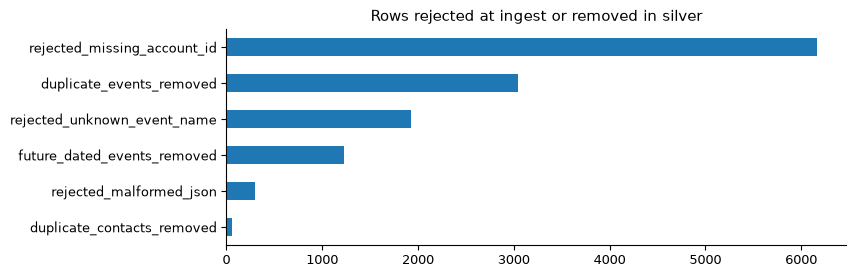

8,385 of 630,208 event lines were rejected at ingest (1.3%).


,stage,measure,row_count
0,ingest,event_lines_received,630208
1,ingest,rejected_malformed_json,299
2,ingest,rejected_missing_account_id,6164
3,ingest,rejected_unknown_event_name,1922
4,ingest,events_loaded_to_bronze,621823
5,silver,duplicate_events_removed,3042
6,silver,future_dated_events_removed,1226
7,silver,late_arriving_events_kept,615
8,silver,events_in_silver,617555
9,silver,duplicate_contacts_removed,60


In [8]:
quality = query(
    "SELECT stage, measure, row_count FROM gold.dq_summary ORDER BY sort_order, measure"
)
caught = quality[quality["measure"].str.contains("rejected|removed")].set_index("measure")
axis = caught["row_count"].sort_values().plot.barh(
    figsize=(8, 2.8), title="Rows rejected at ingest or removed in silver"
)
axis.set_ylabel("")
plt.show()

received = quality.loc[quality["measure"] == "event_lines_received", "row_count"].iloc[0]
rejected = quality.loc[quality["measure"].str.startswith("rejected"), "row_count"].sum()
share = rejected / received
print(f"{rejected:,} of {received:,} event lines were rejected at ingest ({share:.1%}).")
quality

**Reading.** Bad rows are rejected with a reason and kept in a dead-letter table; none is dropped silently. A consequence worth knowing: when the rejected event is a setup step, the account looks one step behind until the dead letter is replayed. Seats are read from the licence snapshot instead of from events, and match exactly.

## Validation only: do the scores track the simulator's hidden state?

The simulator keeps a hidden `momentum` for each account. It drives usage and churn and is never exported to the pipeline. Comparing it with the scores shows whether they measure something real. In a real company this check does not exist; the equivalent is the back-test in sections 4 and 5.

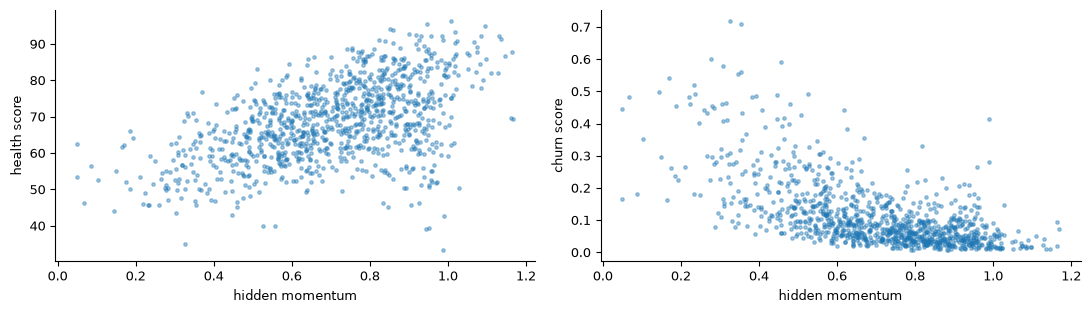

,correlation
Health score and hidden momentum,0.51
Churn score and hidden momentum,-0.63
Churn score and true daily churn risk (rank),0.60


In [9]:
hidden = pd.read_csv(DATA_DIR / "ground_truth" / "daily_hidden_state.csv", parse_dates=["date"])
latest = hidden[hidden["date"] == hidden["date"].max()]
merged = accounts.merge(latest, on="account_id")

figure, (left, right) = plt.subplots(1, 2, figsize=(11, 3.2))
left.scatter(merged["momentum"], merged["health_score"], s=6, alpha=0.4)
left.set_xlabel("hidden momentum")
left.set_ylabel("health score")
right.scatter(merged["momentum"], merged["churn_risk_score"], s=6, alpha=0.4)
right.set_xlabel("hidden momentum")
right.set_ylabel("churn score")
plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "correlation": {
            "Health score and hidden momentum": merged["health_score"].corr(merged["momentum"]),
            "Churn score and hidden momentum": merged["churn_risk_score"].corr(merged["momentum"]),
            "Churn score and true daily churn risk (rank)": merged["churn_risk_score"].corr(
                merged["churn_hazard"], method="spearman"
            ),
        }
    }
).round(2)

## What this analysis changed in the build

- The pilot segment is the uncovered tier, because that is where accounts outnumber people (section 1).
- Plays are triggered by signals, and each signal was kept only because it points the right way (section 4).
- The churn flag is the top of the model's ranking, cut where the team's capacity ends; the health score stays as the readable explanation (section 5).
- Setup steps are read with the dead letter in mind, and seats come from the licence snapshot (section 6).

In [10]:
con.close()